# Học phân loại nhiều lớp với dữ liệu hoa Iris

Notebook này dạy từng bước: KNN, logistic regression nhiều lớp, SVM và PCA. Mỗi bước có phần giải thích, việc cần làm và kết quả mong đợi để bạn tự kiểm tra.

Dữ liệu: 150 bông hoa thuộc 3 loài (setosa, versicolor, virginica). Mỗi bông có 4 số đo tính bằng cm: chiều dài và chiều rộng của đài hoa (sepal), chiều dài và chiều rộng của cánh hoa (petal). Nguồn: bộ Iris của Fisher (1936), lấy từ scikit-learn.

Chuẩn bị:
1. Đặt file data2.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib seaborn scikit-learn

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. df.shape trả về (số dòng, số cột).

Kết quả mong đợi: (150, 5).

In [2]:
df = pd.read_csv('data2.csv')
print(df.shape)

(150, 5)


## Bước 2: Xem tổng quan

Mục tiêu: xem vài dòng đầu, kiểu dữ liệu, giá trị thiếu và số mẫu mỗi loài.

Kiến thức: value_counts() đếm số lần xuất hiện của mỗi giá trị. Một bộ dữ liệu cân bằng có số mẫu mỗi lớp gần bằng nhau.

Kết quả mong đợi: 4 cột số, 1 cột chữ (species), 0 ô trống, mỗi loài 50 mẫu.

Câu hỏi: dữ liệu cân bằng thì accuracy có đáng tin hơn so với dữ liệu lệch không? Vì sao?

In [3]:
print(df.head())
df.info()
print('Số ô trống:', df.isna().sum().sum())
print(df['species'].value_counts())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
Số ô trống: 0
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Bước 3: So sánh trung bình theo loài

Mục tiêu: tìm số đo nào tách các loài rõ nhất.

Kiến thức: groupby("species").mean() tính trung bình của từng cột cho mỗi loài. Cột nào có trung bình rất khác nhau giữa các loài thì có khả năng phân loại tốt.

Kết quả mong đợi: petal_length và petal_width khác nhau nhiều nhất: setosa có petal_length trung bình 1,46, versicolor 4,26, virginica 5,55. Sepal_width gần như giống nhau giữa các loài (2,77 đến 3,43).

Câu hỏi: nhìn bảng, bạn đoán cột nào sẽ quan trọng nhất cho mô hình?

In [4]:
print(df.groupby('species').mean().round(2))

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa              5.01         3.43          1.46         0.25
versicolor          5.94         2.77          4.26         1.33
virginica           6.59         2.97          5.55         2.03


## Bước 4: Pairplot

Mục tiêu: nhìn mọi cặp số đo trên cùng một hình.

Kiến thức: sns.pairplot vẽ scatter cho mỗi cặp cột và histogram trên đường chéo. hue tô màu theo nhãn.

Kết quả mong đợi: setosa tách hẳn khỏi hai loài còn lại ở các hình có petal. Versicolor và virginica chồng lên nhau một phần.

Câu hỏi: nếu chỉ được dùng một hình scatter để phân loại, bạn chọn cặp cột nào?

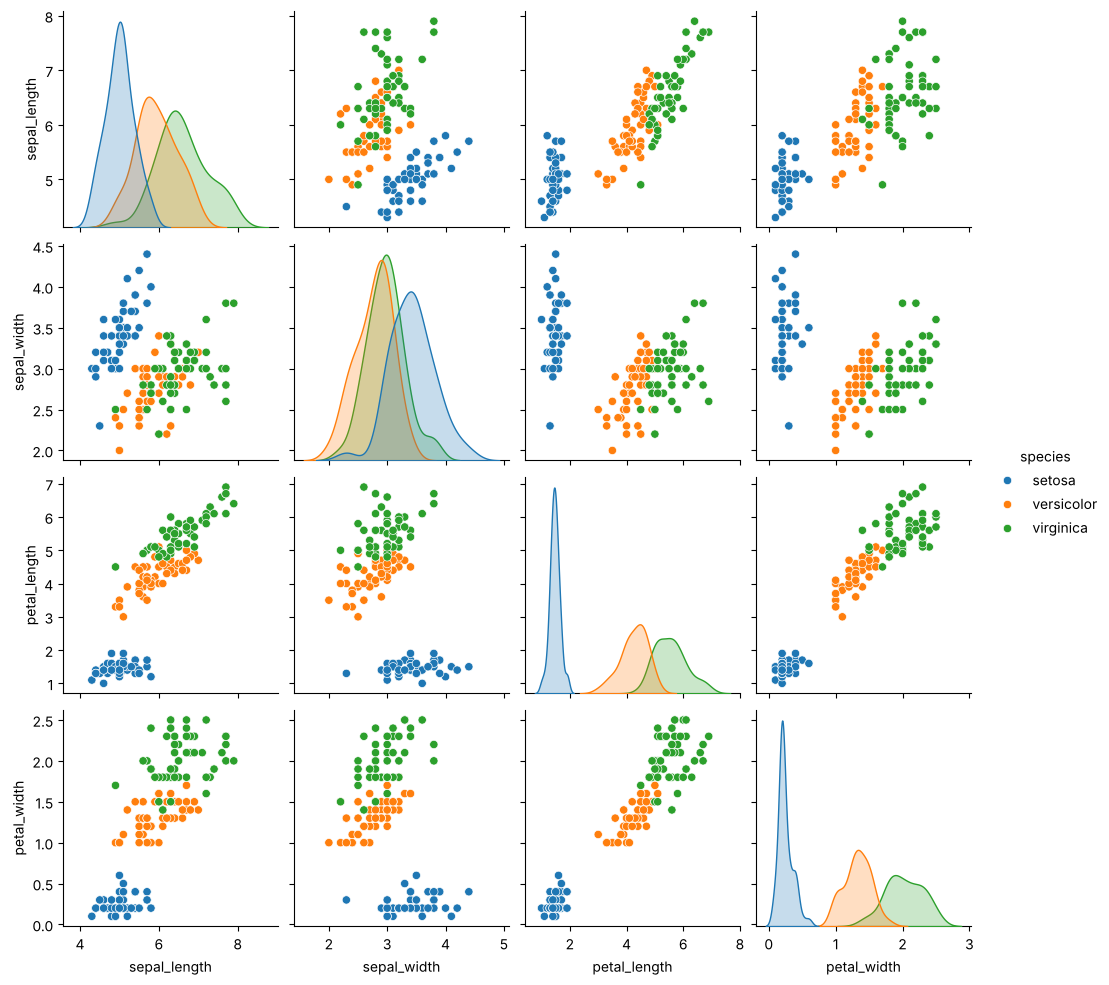

In [5]:
sns.pairplot(df, hue='species')
plt.show()

## Bước 5: Tách X, y và chia train/test

Mục tiêu: tách feature và nhãn, rồi giữ 30% làm tập test.

Kiến thức: stratify=y giữ tỷ lệ các loài giống nhau ở hai tập. Với 150 mẫu, test 30% cho 45 mẫu, mỗi loài 15.

Kết quả mong đợi: X_train có 105 dòng, X_test có 45 dòng, mỗi loài trong y_test có 15 mẫu.

In [6]:
X = df.drop(columns='species')
y = df['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_test.value_counts())

(105, 4) (45, 4)
species
virginica     15
versicolor    15
setosa        15
Name: count, dtype: int64


## Bước 6: Baseline

Mục tiêu: biết mức accuracy thấp nhất mà một mô hình phải vượt qua.

Kiến thức: DummyClassifier(strategy="most_frequent") luôn đoán lớp xuất hiện nhiều nhất. Với 3 lớp cân bằng, nó đạt khoảng 1/3.

Kết quả mong đợi: accuracy khoảng 0,333.

In [7]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print('Baseline accuracy:', round(dummy.score(X_test, y_test), 3))

Baseline accuracy: 0.333


## Bước 7: Chuẩn hóa dữ liệu

Mục tiêu: đưa các cột về cùng thang đo trước khi dùng mô hình dựa trên khoảng cách.

Kiến thức: StandardScaler trừ trung bình rồi chia độ lệch chuẩn, nên mỗi cột có trung bình 0 và độ lệch chuẩn 1. Chỉ fit trên tập train, sau đó dùng transform cho tập test. Nếu fit trên toàn bộ dữ liệu, thông tin của tập test sẽ rò rỉ vào mô hình (data leakage).

Kết quả mong đợi: trung bình của X_train_s bằng 0, độ lệch chuẩn bằng 1 ở cả 4 cột. Trên X_test_s, các con số chỉ gần 0 và gần 1.

Câu hỏi: tại sao trên tập test trung bình không đúng bằng 0?

In [8]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Train mean:', X_train_s.mean(axis=0).round(2), 'std:', X_train_s.std(axis=0).round(2))
print('Test  mean:', X_test_s.mean(axis=0).round(2), 'std:', X_test_s.std(axis=0).round(2))

Train mean: [ 0. -0. -0. -0.] std: [1. 1. 1. 1.]
Test  mean: [-0.12  0.02 -0.05 -0.03] std: [0.86 0.84 0.97 0.94]


## Bước 8: KNN với k = 5

Mục tiêu: huấn luyện mô hình K-Nearest Neighbors đầu tiên.

Kiến thức: KNN không học tham số. Khi dự đoán một điểm mới, nó tìm k điểm gần nhất trong tập train và lấy nhãn chiếm đa số. Khoảng cách mặc định là Euclid, nên thang đo của các cột ảnh hưởng trực tiếp đến kết quả.

Kết quả mong đợi: accuracy khoảng 0,911, tức là đúng 41 trên 45 mẫu.

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
print('KNN k=5 accuracy:', round(knn.score(X_test_s, y_test), 3))

KNN k=5 accuracy: 0.911


## Bước 9: Chọn k bằng cross-validation

Mục tiêu: thử nhiều giá trị k và chọn k tốt nhất mà không nhìn vào tập test.

Kiến thức: make_pipeline(StandardScaler(), KNeighborsClassifier(k)) gộp chuẩn hóa và mô hình, nên trong mỗi fold scaler chỉ fit trên phần train của fold đó. cross_val_score chạy 5 fold trên tập train. k nhỏ dễ overfit, k quá lớn thì mô hình quá đơn giản.

Kết quả mong đợi: k = 7 cho CV accuracy cao nhất, khoảng 0,962. Khi k lớn hơn 15, accuracy giảm dần xuống khoảng 0,876 ở k = 25.

Câu hỏi: vì sao không chọn k dựa trên accuracy của tập test?

1 0.943
3 0.952
5 0.933
7 0.962
9 0.952
11 0.952
13 0.943
15 0.924
17 0.905
19 0.895
21 0.886
23 0.876
25 0.876
best_k = 7


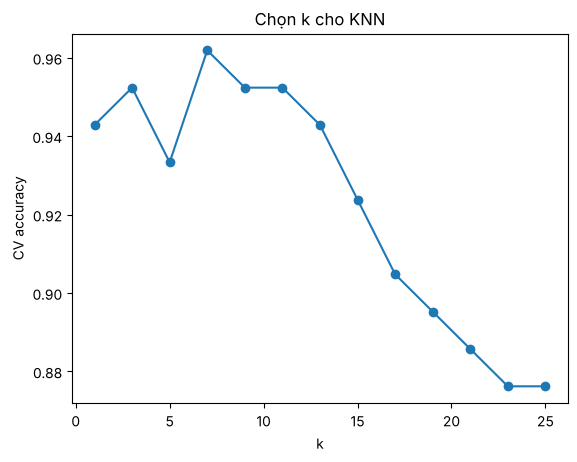

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {}
for k in range(1, 26, 2):
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores[k] = cross_val_score(pipe, X_train, y_train, cv=cv).mean()
for k, s in scores.items():
    print(k, round(s, 3))
best_k = max(scores, key=scores.get)
print('best_k =', best_k)

plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.xlabel('k')
plt.ylabel('CV accuracy')
plt.title('Chọn k cho KNN')
plt.show()

## Bước 10: Confusion matrix

Mục tiêu: xem mô hình nhầm loài nào với loài nào.

Kiến thức: confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán. Các ô ngoài đường chéo là lỗi. classification_report cho precision, recall và F1 của từng lớp.

Kết quả mong đợi: setosa đúng hết. Accuracy khoảng 0,93. Virginica có recall 0,80, tức là 3 bông virginica bị đoán thành versicolor.

Câu hỏi: lỗi (nếu có) rơi vào cặp loài nào? Có khớp với pairplot ở bước 4 không?

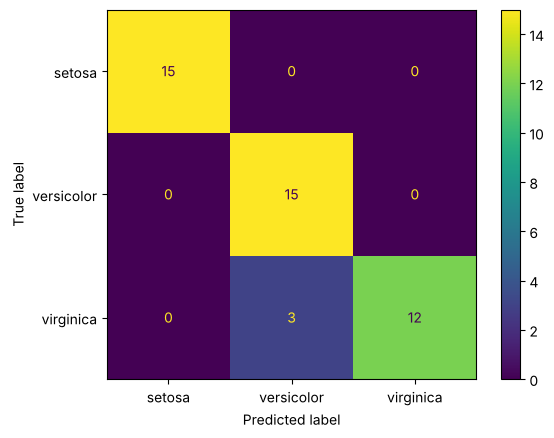

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.83      1.00      0.91        15
   virginica       1.00      0.80      0.89        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



In [11]:
knn_best = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn_best.fit(X_train, y_train)
pred_knn = knn_best.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn)
plt.show()
print(classification_report(y_test, pred_knn))

## Bước 11: Logistic regression nhiều lớp

Mục tiêu: dùng logistic regression cho 3 lớp và đọc xác suất dự đoán.

Kiến thức: với nhiều lớp, sklearn dùng hàm softmax: mỗi lớp có một bộ hệ số, và xác suất của 3 lớp cộng lại bằng 1. coef_ có kích thước (số lớp, số feature).

Kết quả mong đợi: accuracy khoảng 0,911. coef_ có kích thước (3, 4). Với bông hoa đầu tiên, xác suất virginica khoảng 0,899 và nhãn thật là virginica.

Câu hỏi: với bông hoa đầu tiên trong tập test, mô hình chắc chắn đến mức nào?

In [12]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
print('Logistic accuracy:', round(logreg.score(X_test, y_test), 3))
print('coef_ shape:', logreg[-1].coef_.shape)
print(logreg.classes_)
print(logreg.predict_proba(X_test.iloc[[0]]).round(3), 'nhãn thật:', y_test.iloc[0])

Logistic accuracy: 0.911
coef_ shape: (3, 4)
['setosa' 'versicolor' 'virginica']
[[0.    0.101 0.899]] nhãn thật: virginica


## Bước 12: SVM tuyến tính và SVM RBF

Mục tiêu: so sánh SVM với kernel tuyến tính và kernel RBF.

Kiến thức: SVM tìm đường biên có lề (margin) rộng nhất giữa các lớp. Kernel linear cho đường biên thẳng. Kernel rbf cho đường biên cong. C lớn thì phạt lỗi mạnh, lề hẹp hơn và dễ overfit hơn.

Kết quả mong đợi: linear: CV khoảng 0,962, test khoảng 0,911. rbf: CV khoảng 0,971, test khoảng 0,933.

In [13]:
for kernel in ['linear', 'rbf']:
    svm = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    cv_acc = cross_val_score(svm, X_train, y_train, cv=cv).mean()
    svm.fit(X_train, y_train)
    print(kernel, '| CV accuracy:', round(cv_acc, 3), '| test accuracy:', round(svm.score(X_test, y_test), 3))

linear | CV accuracy: 0.962 | test accuracy: 0.911
rbf | CV accuracy: 0.971 | test accuracy: 0.933


## Bước 13: Tìm C và gamma bằng GridSearchCV

Mục tiêu: tự động thử nhiều tổ hợp tham số và chọn tổ hợp tốt nhất theo cross-validation.

Kiến thức: GridSearchCV thử mọi tổ hợp trong param_grid. Tên tham số trong pipeline có dạng tên_bước__tên_tham_số, ví dụ svc__C. best_params_ và best_score_ cho tổ hợp tốt nhất.

Kết quả mong đợi: best params là C = 10 và gamma = 0,01, CV accuracy khoảng 0,981, test accuracy khoảng 0,911. Test accuracy thấp hơn SVM RBF mặc định ở bước 12 dù CV cao hơn.

Câu hỏi: CV accuracy tăng nhưng test accuracy lại giảm. Với tập test chỉ 45 mẫu, chênh lệch 1 mẫu có ý nghĩa không? Bạn tin con số nào hơn?

In [14]:
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')),
                    {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1, 1]}, cv=cv)
grid.fit(X_train, y_train)
print('best params:', grid.best_params_)
print('best CV accuracy:', round(grid.best_score_, 3))
print('test accuracy:', round(grid.best_estimator_.score(X_test, y_test), 3))

best params: {'svc__C': 10, 'svc__gamma': 0.01}
best CV accuracy: 0.981
test accuracy: 0.911


## Bước 14: PCA: giảm từ 4 chiều xuống 2 chiều

Mục tiêu: tìm 2 trục mới giữ được nhiều thông tin nhất của 4 cột ban đầu.

Kiến thức: PCA (principal component analysis) tạo các trục mới là tổ hợp tuyến tính của các cột cũ. Trục thứ nhất giữ nhiều phương sai nhất. explained_variance_ratio_ cho biết mỗi trục giữ bao nhiêu phần trăm phương sai. PCA cần chuẩn hóa trước, nếu không cột có đơn vị lớn sẽ chiếm ưu thế.

Kết quả mong đợi: PC1 giữ khoảng 73,0% phương sai, PC2 khoảng 22,9%, cộng lại khoảng 95,8%. PC1 có trọng số lớn ở petal_length, petal_width và sepal_length. PC2 chủ yếu là sepal_width (0,923).

Câu hỏi: 2 trục đầu giữ bao nhiêu phần trăm thông tin? Có đủ để vẽ dữ liệu lên mặt phẳng không?

In [15]:
X_all_s = StandardScaler().fit_transform(X)
pca = PCA()
X_pca = pca.fit_transform(X_all_s)
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))
print('Cumulative:', np.cumsum(pca.explained_variance_ratio_).round(3))
print(pd.DataFrame(pca.components_[:2], columns=X.columns, index=['PC1', 'PC2']).round(3))

Explained variance ratio: [0.73  0.229 0.037 0.005]
Cumulative: [0.73  0.958 0.995 1.   ]
     sepal_length  sepal_width  petal_length  petal_width
PC1         0.521       -0.269         0.580        0.565
PC2         0.377        0.923         0.024        0.067


## Bước 15: Vẽ dữ liệu trên 2 trục PCA

Mục tiêu: nhìn cả 150 bông hoa trên một hình 2 chiều.

Kiến thức: X_pca[:, 0] là tọa độ trên PC1, X_pca[:, 1] là tọa độ trên PC2. sns.scatterplot với hue=y tô màu theo loài.

Kết quả mong đợi: 3 cụm theo PC1. Setosa nằm riêng một phía. Versicolor và virginica nằm gần nhau và chạm nhau ở giữa.

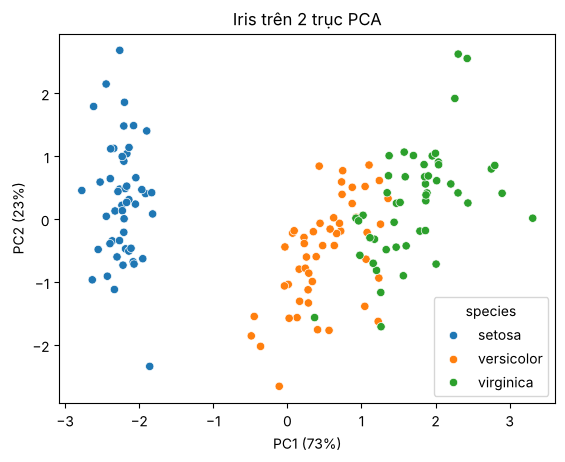

In [16]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title('Iris trên 2 trục PCA')
plt.show()

## Bước 16: Mô hình trên 2 trục PCA

Mục tiêu: kiểm tra xem bỏ bớt 2 chiều có làm giảm accuracy không.

Kiến thức: đặt PCA(n_components=2) vào pipeline giữa scaler và mô hình. Khi đó PCA chỉ fit trên tập train trong mỗi fold.

Kết quả mong đợi: 2 PC: CV accuracy khoảng 0,895, test accuracy khoảng 0,889. Logistic với 4 cột có CV khoảng 0,981.

Câu hỏi: giảm chiều có lợi gì khi dữ liệu có hàng trăm cột thay vì 4 cột?

In [17]:
pca_lr = make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000))
print('CV accuracy (2 PC):', round(cross_val_score(pca_lr, X_train, y_train, cv=cv).mean(), 3))
pca_lr.fit(X_train, y_train)
print('Test accuracy (2 PC):', round(pca_lr.score(X_test, y_test), 3))
print('CV accuracy (4 cột):', round(cross_val_score(logreg, X_train, y_train, cv=cv).mean(), 3))

CV accuracy (2 PC): 0.895
Test accuracy (2 PC): 0.889
CV accuracy (4 cột): 0.981


## Bước 17: Bảng so sánh các mô hình

Mục tiêu: ghép kết quả của tất cả mô hình vào một bảng.

Kiến thức: với dữ liệu nhỏ như Iris, test accuracy trên 45 mẫu dao động mạnh: sai thêm 1 mẫu là mất 2,2 điểm phần trăm. Vì vậy nên xem cả CV accuracy và độ lệch chuẩn của nó.

Kết quả mong đợi: các mô hình (trừ baseline) có CV mean từ 0,895 đến 0,981. KNN k = 7 có test accuracy cao nhất (0,933), còn Logistic và SVM RBF tuned có CV mean cao nhất (0,981).

Câu hỏi: các mô hình có khác nhau thật sự không, hay chênh lệch nằm trong độ lệch chuẩn?

In [18]:
models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    f'KNN k={best_k}': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'SVM linear': make_pipeline(StandardScaler(), SVC(kernel='linear')),
    'SVM RBF tuned': grid.best_estimator_,
    'Logistic 2 PC': make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=1000)),
}
rows = []
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv)
    model.fit(X_train, y_train)
    rows.append({'Mô hình': name, 'CV mean': round(s.mean(), 3), 'CV std': round(s.std(), 3),
                 'Test acc': round(model.score(X_test, y_test), 3)})
print(pd.DataFrame(rows).to_string())

         Mô hình  CV mean  CV std  Test acc
0       Baseline    0.333   0.000     0.333
1        KNN k=7    0.962   0.056     0.933
2       Logistic    0.981   0.023     0.911
3     SVM linear    0.962   0.036     0.911
4  SVM RBF tuned    0.981   0.023     0.911
5  Logistic 2 PC    0.895   0.082     0.889


## Bước 18: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Chạy KNN với best_k nhưng không chuẩn hóa dữ liệu. Accuracy thay đổi thế nào? Với Iris, các cột đều tính bằng cm, vậy chuẩn hóa có còn quan trọng không?
2. Chỉ dùng 2 cột petal_length và petal_width. So sánh accuracy với khi dùng đủ 4 cột.
3. Đổi KNeighborsClassifier(weights='distance'). Kết quả có khác không?
4. Viết ba câu tiếng Anh tóm tắt bảng ở bước 17. Ví dụ mở đầu: "All models except the baseline reached a cross-validated accuracy above ..."
